# Лабораторная работа №3
Арифметические вычисления.

Монгуш Темир Мергенович · ИУ5-35Б · Вариант 11

Задания 1–3. Выражение: `((((c/b)+a)/c)+a)`. Деление целочисленное.

[Условие](https://github.com/junaart/System_programming/blob/master/Lab_3/Lab_3.ipynb)

Ячейки выполняются сверху вниз. Проверено в Linux x86-64 с FASM.

## Подготовка

In [1]:
%%bash
set -e
if ! dpkg -s fasm binutils gcc file >/dev/null 2>&1; then
    SUDO=()
    if [ "$(id -u)" -ne 0 ]; then SUDO=(sudo); fi
    "${SUDO[@]}" apt-get update -qq
    "${SUDO[@]}" env DEBIAN_FRONTEND=noninteractive apt-get install -y -qq fasm binutils gcc file
fi
mkdir -p Lab_3
uname -sm
fasm | head -n 1
gcc --version | head -n 1

Linux x86_64
flat assembler  version 1.73.32
gcc (Debian 14.2.0-19) 14.2.0


## Вариант

In [2]:
import random as rd
Variant = 11
rd.seed(Variant)
operations = ['-','+','*','/']
operands = ['a','b','c']
count = rd.randint(3,5)
expression = operands[rd.randint(0,2)]
for _ in range(count):
    operation = operations[rd.randint(0,3)]
    operand = operands[rd.randint(0,2)]
    expression = '(' + expression + operation + operand + ')'
print(expression)
assert expression == '((((c/b)+a)/c)+a)'

((((c/b)+a)/c)+a)


## Процедуры ввода, вывода и преобразования чисел

In [3]:
%%writefile Lab_3/common.inc
; Linux x86-64. Вспомогательные процедуры по образцу func.asm из лекций.
; rbx, rbp, r12-r15 сохраняются; остальные регистры могут изменяться.
; parse_uint: rsi -> строка, rax <- число; строгая проверка uint64.
parse_uint:
    xor eax, eax
    mov r8d, 10
    cmp byte [rsi], 0
    je error
.loop:
    movzx r9d, byte [rsi]
    test r9b, r9b
    jz .done
    sub r9d, '0'
    cmp r9d, 9
    ja error
    mul r8
    test rdx, rdx
    jnz error
    add rax, r9
    jc error
    inc rsi
    jmp .loop
.done:
    ret

; parse_int: rsi -> строка, rax <- int64.
parse_int:
    xor r10d, r10d
    cmp byte [rsi], '-'
    jne .positive
    inc rsi
    inc r10d
    jmp .convert
.positive:
    cmp byte [rsi], '+'
    jne .convert
    inc rsi
.convert:
    call parse_uint
    mov r9, 7FFFFFFFFFFFFFFFh
    add r9, r10
    cmp rax, r9
    ja error
    test r10d, r10d
    jz .done
    neg rax
.done:
    ret

; read_uint: ввод одной строки через read(0,...), результат в rax.
read_uint:
    xor r10d, r10d
.loop:
    xor eax, eax
    xor edi, edi
    lea rsi, [input_buffer+r10]
    mov edx, 1
    syscall
    test rax, rax
    js error
    jz .done
    cmp byte [rsi], 10
    je .done
    inc r10
    cmp r10, 31
    jae error
    jmp .loop
.done:
    mov byte [input_buffer+r10], 0
    mov rsi, input_buffer
    jmp parse_uint

; print_int: вывести int64 из rax и перевод строки через write.
print_int:
    xor r10d, r10d
    test rax, rax
    jns .convert
    inc r10d
    neg rax
.convert:
    mov r8d, 10
    mov rsi, number_buffer+31
    mov byte [rsi], 10
    mov edx, 1
.loop:
    push rdx
    xor edx, edx
    div r8
    add dl, '0'
    dec rsi
    mov [rsi], dl
    pop rdx
    inc rdx
    test rax, rax
    jnz .loop
    test r10d, r10d
    jz .write
    dec rsi
    mov byte [rsi], '-'
    inc rdx
.write:
    mov edi, 1
    mov eax, 1
    syscall
    ret

exit:
    mov eax, 60
    xor edi, edi
    syscall
error:
    mov eax, 1
    mov edi, 2
    mov rsi, error_message
    mov edx, error_length
    syscall
    mov eax, 60
    mov edi, 1
    syscall

section '.data' writable
error_message db 'Invalid input or I/O error',10
error_length = $-error_message
section '.bss' writable
input_buffer rb 32
number_buffer rb 32

Writing Lab_3/common.inc


## 1. ASCII-код символа из командной строки

In [4]:
%%writefile Lab_3/ascii.asm
format ELF64
public _start
section '.text' executable
_start:
    cmp qword [rsp], 2
    jne error
    mov rsi, [rsp+16]
    cmp byte [rsi], 0
    je error
    cmp byte [rsi+1], 0
    jne error
    movzx eax, byte [rsi]
    cmp eax, 127
    ja error
    call print_int
    jmp exit
include 'common.inc'

Writing Lab_3/ascii.asm


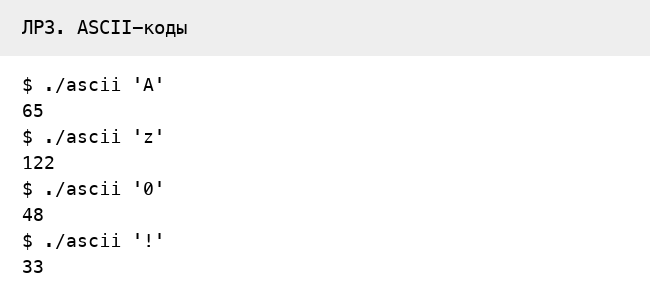

In [5]:
%%bash
set -e
cd Lab_3
fasm ascii.asm ascii.o >/dev/null
ld ascii.o -o ascii
for ch in A z 0 '!'; do
    echo "$ ./ascii '$ch'"
    ./ascii "$ch"
done

## 2. Вычисление выражения на ассемблере

In [6]:
%%writefile Lab_3/expression.asm
; Вариант 11: ((((c/b)+a)/c)+a). Целочисленное деление.
format ELF64
public _start
section '.text' executable
_start:
    cmp qword [rsp], 4
    jne error
    mov rsi, [rsp+16]
    call parse_int
    mov r12, rax                     ; a
    mov rsi, [rsp+24]
    call parse_int
    mov r13, rax                     ; b
    mov rsi, [rsp+32]
    call parse_int
    mov r14, rax                     ; c
    test r13, r13
    jz error
    test r14, r14
    jz error
    mov rax, r14
    mov rbx, r13
    call divide
    add rax, r12
    jo error
    mov rbx, r14
    call divide
    add rax, r12
    jo error
    call print_int
    jmp exit
divide:
    mov rdx, 8000000000000000h
    cmp rax, rdx
    jne .ok
    cmp rbx, -1
    je error
.ok:
    cqo
    idiv rbx
    ret
include 'common.inc'

Writing Lab_3/expression.asm


## 3. Программа на C

In [7]:
%%writefile Lab_3/expression.c
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <errno.h>
#include <inttypes.h>
static int64_t number(const char *s) {
    char *end;
    errno = 0;
    int64_t x = strtoll(s, &end, 10);
    if (errno || !*s || *end) exit(1);
    return x;
}
int main(int argc, char **argv) {
    if (argc != 4) return 1;
    int64_t a = number(argv[1]), b = number(argv[2]), c = number(argv[3]);
    if (!b || !c || (c == INT64_MIN && b == -1)) return 1;
    int64_t x;
    if (__builtin_add_overflow(c / b, a, &x)) return 1;
    if (x == INT64_MIN && c == -1) return 1;
    if (__builtin_add_overflow(x / c, a, &x)) return 1;
    printf("%" PRId64 "\n", x);
    return 0;
}

Writing Lab_3/expression.c


In [8]:
%%bash
set -e
cd Lab_3
fasm expression.asm expression.o >/dev/null
ld expression.o -o expression
gcc -Wall -Wextra -O0 expression.c -o expression_c

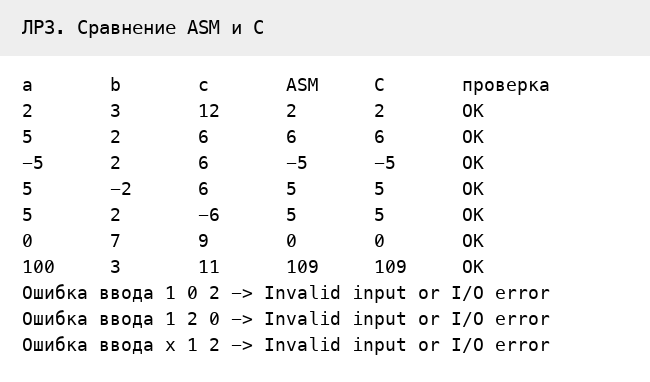

In [9]:
from pathlib import Path
import subprocess
p = Path('Lab_3').resolve()
def trunc(x,y):
    return abs(x)//abs(y) * (-1 if (x<0) != (y<0) else 1)
print('a       b       c       ASM     C       проверка')
for a,b,c in [(2,3,12),(5,2,6),(-5,2,6),(5,-2,6),(5,2,-6),(0,7,9),(100,3,11)]:
    expected = trunc(trunc(c,b)+a,c)+a
    args = list(map(str,(a,b,c)))
    asm = subprocess.check_output([str(p/'expression'),*args],text=True).strip()
    cpp = subprocess.check_output([str(p/'expression_c'),*args],text=True).strip()
    assert asm == cpp == str(expected)
    print(f'{a:<8}{b:<8}{c:<8}{asm:<8}{cpp:<8}OK')
for args in [('1','0','2'),('1','2','0'),('x','1','2')]:
    r = subprocess.run([str(p/'expression'),*args],capture_output=True,text=True)
    assert r.returncode != 0
    print('Ошибка ввода', ' '.join(args), '->', r.stderr.strip())